# 07. Scenarios: what would cutting storm overflow spills achieve?

The fitted champion models are re-scored with spill features scaled down: spill hours and counts,
and the number of frequently spilling overflows. Everything else is held fixed. For comparison, the same is
done for sewage works effluent and urban land.

**Read these as model-based expectations, not causal effects.** The models learned associations across
rivers. Monotone constraints guarantee the direction, but the size of each effect may still borrow
from correlated, unmeasured pressures.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

In [2]:
s = pd.read_csv(T / "scenarios.csv")
s[["target", "scenario", "expected_good_base", "expected_good", "extra_good_wbs"]].round(1)

,target,scenario,expected_good_base,expected_good,extra_good_wbs
0,eco_good,spills -25%,568.5,573.1,4.6
1,eco_good,spills -50%,568.5,580.5,12.0
2,eco_good,spills -75%,568.5,589.4,20.9
3,eco_good,spills -100%,568.5,621.0,52.5
4,eco_good,urban land -50% (yardstick),568.5,640.8,72.3
5,eco_good,sewage works effluent -50% (yardstick),568.5,580.3,11.8
6,inv_good,spills -25%,2856.5,2870.7,14.2
7,inv_good,spills -50%,2856.5,2887.4,30.9
8,inv_good,spills -75%,2856.5,2900.8,44.4
9,inv_good,spills -100%,2856.5,2916.4,59.9


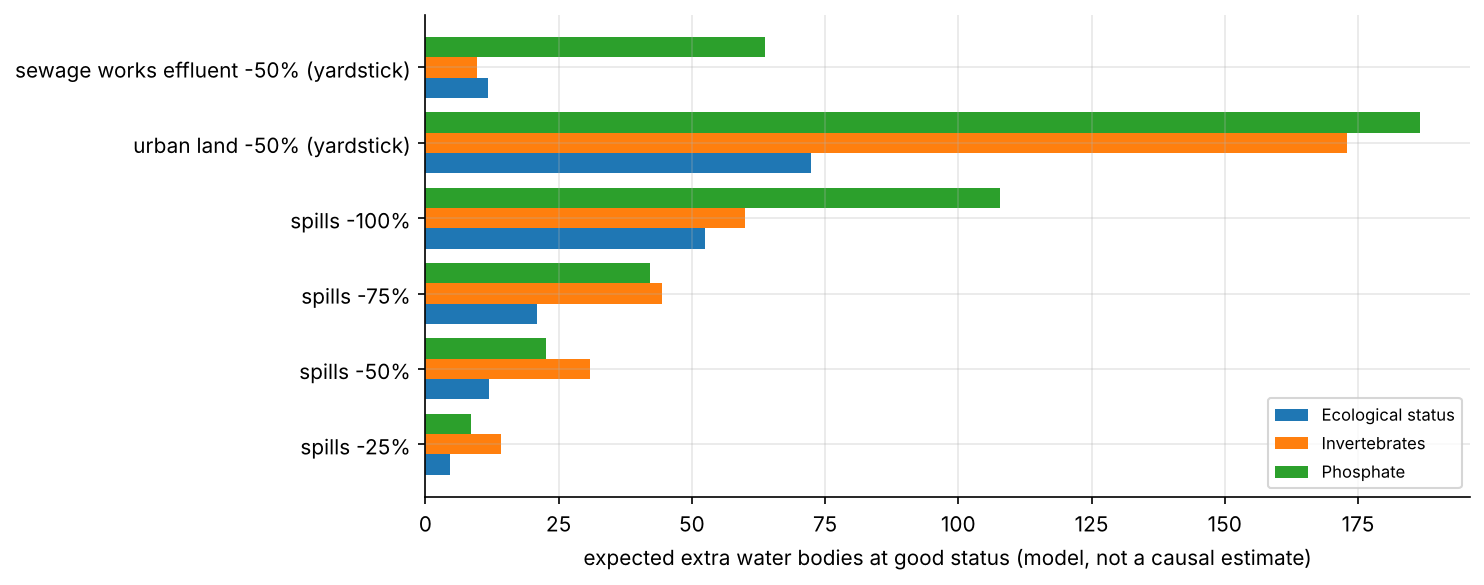

In [3]:
display(Image(FIG / "scenarios.png"))

## Where would stopping spills matter most? (invertebrates)

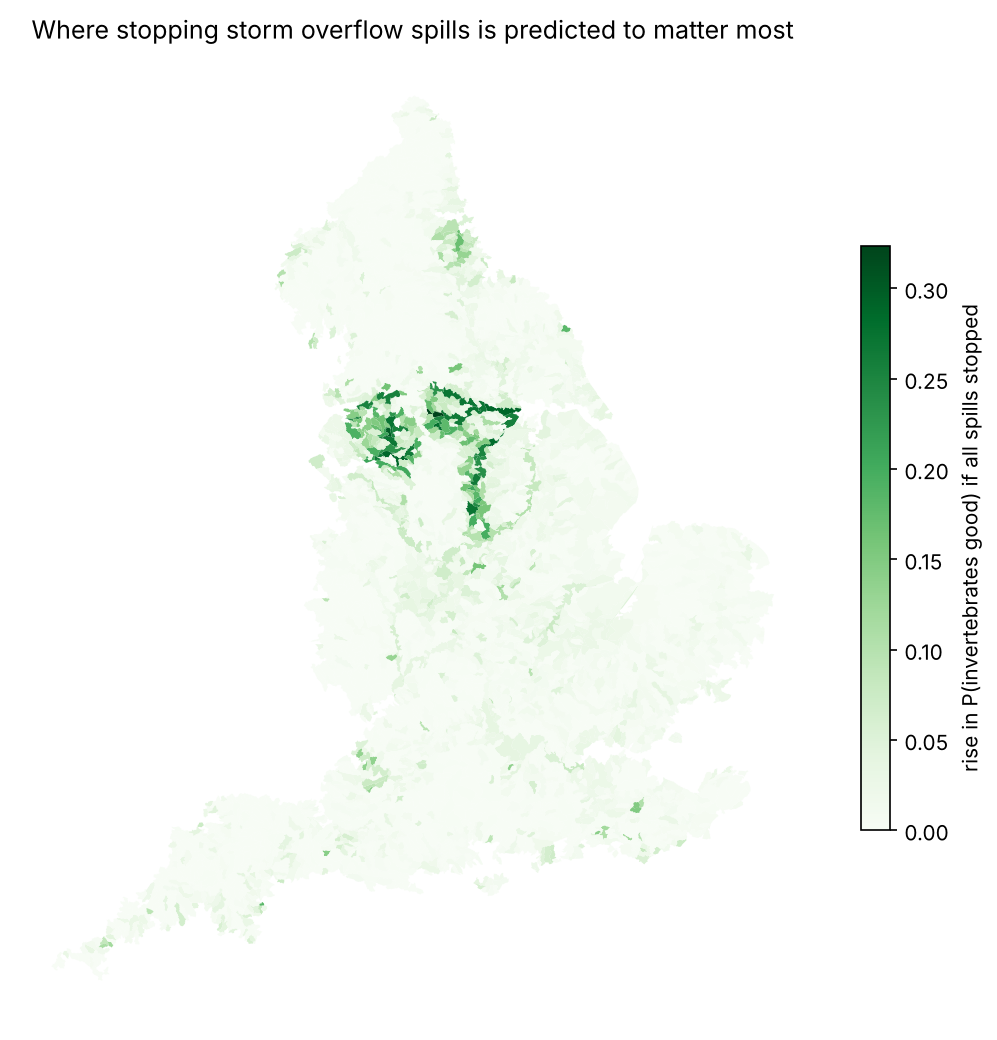

In [4]:
display(Image(FIG / "map_spill_gain_inv.png"))

In [5]:
p = pd.read_parquet(T / "scenario_per_wb.parquet")
top = (p[p.target == "inv_good"].merge(t[["water_body_id", "name", "management_catchment", "local_n_overflows",
                                         "up_n_overflows", "up_spill_hours", "y_inv"]], on="water_body_id")
       .sort_values("gain", ascending=False).head(20))
top[["name", "management_catchment", "y_inv", "up_n_overflows", "up_spill_hours", "p_base", "p_no_spills", "gain"]].round(2)

,name,management_catchment,y_inv,up_n_overflows,up_spill_hours,p_base,p_no_spills,gain
805,Calder from Ryburn Confluence to River Colne,Aire and Calder,Moderate,137.0,29936.43,0.32,0.64,0.32
2011,Irwell (Roch to Croal),Irwell,Bad,144.0,24000.66,0.29,0.59,0.30
2209,Aire from Fryston Beck to River Ouse,Aire and Calder,Moderate,835.0,116333.42,0.31,0.60,0.29
332,Mersey (upstream of Manchester Ship Canal),Mersey Upper,NaN,256.0,47162.54,0.28,0.57,0.29
3412,Don from River Dearne to Mill Dyke,Don and Rother,Moderate,490.0,72368.16,0.35,0.63,0.28
1677,Holme from New Mill Dike to R Colne,Aire and Calder,Moderate,39.0,8311.43,0.48,0.76,0.28
2015,Irwell (Rossendale STW to Roch),Irwell,Moderate,66.0,10856.48,0.48,0.75,0.27
483,Amber from Alfreton Brook to Derwent,Derwent Derbyshire,Good,61.0,17516.67,0.55,0.82,0.27
103,Calder from River Chald to River Aire,Aire and Calder,Moderate,407.0,64454.75,0.20,0.47,0.27
1496,Aire from Gill Beck (Baildon) to Wyke Beck,Aire and Calder,Moderate,356.0,41143.60,0.25,0.53,0.27


The top of the priority list is local: the Calder, Aire, Irwell, Mersey and Don, the old industrial river
systems of West Yorkshire, Greater Manchester and South Yorkshire. Each has hundreds of overflows upstream, and
the model puts its chance of good invertebrates near 30%, rising to about 60% without spills. The gain is concentrated: the top 200 water bodies (5% of the total) carry about half of the predicted
invertebrate gain. These are places where spills are heavy relative to the river's size, so removing them
could tip the balance. Elsewhere, removing spills leaves the river failing for other reasons: sewage works
effluent, urban runoff, farming.